# SEMMA | Predicting NBA home wins from recent form

Predict the home team's win probability using data available before a regular season game.

[Dataset on Kaggle](https://www.kaggle.com/datasets/nathanlauga/nba-games)

Use a standard CPU runtime and run the cells in order.

Methodology reference: [SAS SEMMA](https://support.sas.com/documentation/cdl/en/emcs/66392/HTML/default/n0pejm83csbja4n1xueveo2uoujy.htm). Kaggle snapshot version: 10.

## Methodology map

| SEMMA stage | Evidence |
| --- | --- |
| Sample | Source, inclusion funnel, time boundaries and coverage |
| Explore | Training distributions, season trends, and data quality |
| Modify | Lagged form, join integrity, feature range, cohort loss |
| Model | Candidate comparison, baseline, validation diagnostics |
| Assess | Frozen holdout, calibration, paired uncertainty, slices and errors |

## Setup

Download the Kaggle archive, check the selected CSVs against their SHA-256 fingerprints, and report the package versions. The fingerprints protect the analysis against changes to the source files.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from importlib.metadata import version

KAGGLE_DATASET = 'nathanlauga/nba-games'
KAGGLE_VERSION = 10
EXPECTED_SHA256 = {'games.csv': 'f3e5a0d6f2cb14d6e45aad85de7d346f90d53407e64d573a975bb0de478aa14a', 'teams.csv': '9b933f7245d6b529e6ea0046444e168fd5c3b59986597f61df7cc1ad63f1c8e9'}
ARTIFACTS = Path(os.environ.get("PROJECT_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)


def load_kaggle_tables():
    archive_path = os.environ.get("PROJECT_DATA_ZIP")
    if archive_path:
        archive = Path(archive_path).read_bytes()
    else:
        url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}?datasetVersionNumber={KAGGLE_VERSION}"
        with urlopen(Request(url, headers={"User-Agent": "CMPE255-notebook/1.0"}), timeout=120) as response:
            archive = response.read()
    tables = {}
    with ZipFile(BytesIO(archive)) as zipped:
        for filename, expected in EXPECTED_SHA256.items():
            content = zipped.read(filename)
            actual = hashlib.sha256(content).hexdigest()
            if actual != expected:
                raise ValueError(f"{filename} changed. Use the archived Kaggle version described in the README.")
            tables[filename] = pd.read_csv(BytesIO(content), na_values=[r"\N"])
    return tables


def save_json(filename, payload):
    (ARTIFACTS / filename).write_text(json.dumps(payload, indent=2) + "\n")


tables = load_kaggle_tables()
print("Python", sys.version.split()[0])
print({name: version(name) for name in ("pandas", "numpy", "scikit-learn", "matplotlib")})
print({name: df.shape for name, df in tables.items()})
print("Kaggle snapshot:", KAGGLE_VERSION)

Python 3.14.7
{'pandas': '3.1.1', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
{'games.csv': (26651, 21), 'teams.csv': (30, 14)}
Kaggle snapshot: 10


## 1. Sample

Select completed regular season games. The NBA game ID uses 002 as its regular season prefix when padded to ten digits. Use seasons before 2017–18 for training, 2017–18 for validation, and 2018–19 for assessment. A time-based split simulates predicting future games. We retain earlier regular season games to build team history.

In [2]:
games = tables["games.csv"]
team_names = tables["teams.csv"].set_index("TEAM_ID")["NICKNAME"]
source_columns = ["GAME_DATE_EST", "GAME_ID", "HOME_TEAM_ID", "VISITOR_TEAM_ID", "PTS_home", "PTS_away", "HOME_TEAM_WINS"]
display(games[source_columns].head(5))
regular_season = games.GAME_ID.astype("int64").astype(str).str.zfill(10).str.startswith("002")
games = games.loc[regular_season & games.GAME_STATUS_TEXT.eq("Final")].dropna(subset=source_columns).copy()
games = games.drop_duplicates("GAME_ID")
games["date"] = pd.to_datetime(games.GAME_DATE_EST)
games = games.loc[games.SEASON.le(2018)].sort_values("date")
print("Selected regular season games:", len(games))

,GAME_DATE_EST,GAME_ID,HOME_TEAM_ID,VISITOR_TEAM_ID,PTS_home,PTS_away,HOME_TEAM_WINS
0,2022-12-22,22200477,1610612740,1610612759,126.0,117.0,1
1,2022-12-22,22200478,1610612762,1610612764,120.0,112.0,1
2,2022-12-21,22200466,1610612739,1610612749,114.0,106.0,1
3,2022-12-21,22200467,1610612755,1610612765,113.0,93.0,1
4,2022-12-21,22200468,1610612737,1610612741,108.0,110.0,0


Selected regular season games: 19398


The historical outcome must agree with the score. Count the completed games by season before requiring team history.

In [3]:
assert games.PTS_home.ne(games.PTS_away).all()
assert games.HOME_TEAM_WINS.eq(games.PTS_home.gt(games.PTS_away)).all()
display(games.groupby("SEASON").size().rename("games_before_history_requirement").to_frame())

,games_before_history_requirement
SEASON,
2003,1189
2004,1230
2005,1230
2006,1230
2007,1230
2008,1230
2009,1230
2010,1230
2011,990


### 1.1 Reconcile sample selection

Count rows after each filter so that a reader can reproduce the starting cohort.

In [4]:
raw_games = tables["games.csv"]
is_regular = raw_games.GAME_ID.astype("int64").astype(str).str.zfill(10).str.startswith("002")
regular_completed = raw_games.loc[is_regular & raw_games.GAME_STATUS_TEXT.eq("Final")]
complete_fields = regular_completed.dropna(subset=source_columns)
unique_games = complete_fields.drop_duplicates("GAME_ID")
sample_flow = pd.Series({
    "raw games": len(raw_games), "completed regular season": len(regular_completed),
    "complete required fields": len(complete_fields), "unique game IDs": len(unique_games),
    "through 2018–19": len(games),
})
display(sample_flow.to_frame("rows"))

,rows
raw games,26651
completed regular season,23273
complete required fields,23273
unique game IDs,23244
through 2018–19,19398


### 1.2 Verify dates and teams

Check that game IDs are unique, the teams differ, and both team keys are available in the team lookup.

In [5]:
assert games.GAME_ID.is_unique and games.date.notna().all()
assert games.HOME_TEAM_ID.ne(games.VISITOR_TEAM_ID).all()
assert games.HOME_TEAM_ID.isin(team_names.index).all()
assert games.VISITOR_TEAM_ID.isin(team_names.index).all()
display(games.groupby("SEASON").date.agg(first="min", last="max", games="size").tail(7))

,first,last,games
SEASON,,,
2012,2012-10-30,2013-04-17,1229
2013,2013-10-29,2014-04-16,1230
2014,2014-10-28,2015-04-15,1230
2015,2015-10-27,2016-04-13,1230
2016,2016-10-25,2017-04-12,1230
2017,2017-10-17,2018-04-11,1230
2018,2018-10-16,2019-04-10,1230


## 2. Explore

Inspect the share of home wins by season using training years. The scores are postgame fields. They label the current outcome and help calculate past form for later games.

,size,mean
SEASON,,
2012,1229,0.611880
2013,1230,0.580488
2014,1230,0.574797
2015,1230,0.588618
2016,1230,0.583740


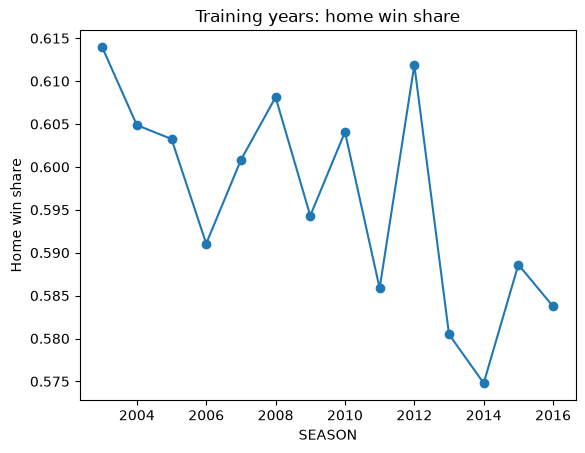

In [6]:
home_share = games.loc[games.SEASON.lt(2017)].groupby("SEASON").HOME_TEAM_WINS.agg(["size", "mean"])
display(home_share.tail())
home_share["mean"].plot(marker="o", title="Training years: home win share", ylabel="Home win share")
plt.show()

### 2.1 Inspect score and margin distributions

Use training seasons for this exploration. The score margin explains the target and is available as an input only for earlier games.

count    16938.00
mean         3.04
std         13.04
min        -51.00
25%         -6.00
50%          4.00
75%         11.00
max         55.00
Name: home point margin, dtype: float64

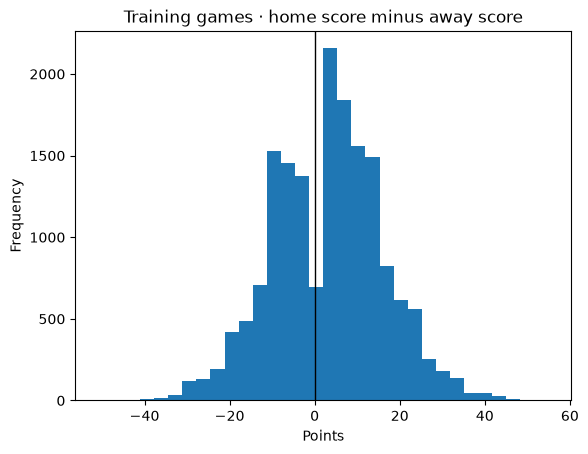

In [7]:
explore_games = games.loc[games.SEASON.lt(2017)]
historical_margin = explore_games.PTS_home - explore_games.PTS_away
display(historical_margin.describe().round(2).rename("home point margin"))
historical_margin.plot.hist(bins=32, title="Training games · home score minus away score", xlabel="Points")
plt.axvline(0, color="black", linewidth=1)
plt.show()

### 2.2 Compare coverage across teams

Sparse teams and incomplete coverage can affect rolling features. Compare games played in each role in the training pool.

In [8]:
team_coverage = pd.concat([
    explore_games.HOME_TEAM_ID.value_counts().rename("home_games"),
    explore_games.VISITOR_TEAM_ID.value_counts().rename("away_games"),
], axis=1).fillna(0).astype(int)
team_coverage["total"] = team_coverage.sum(axis=1)
team_coverage["team"] = team_coverage.index.map(team_names)
display(team_coverage.sort_values("total").head(8))

,home_games,away_games,total,team
1610612766,525,525,1050,Hornets
1610612754,566,565,1131,Pacers
1610612738,565,566,1131,Celtics
1610612739,566,566,1132,Cavaliers
1610612749,566,566,1132,Bucks
1610612757,566,566,1132,Trail Blazers
1610612742,566,566,1132,Mavericks
1610612737,566,566,1132,Hawks


## 3. Modify

A rolling statistic summarizes the most recent records. For each team, calculate the average of its five most recent wins and point margins. Shift the values by one game so the current score cannot influence its own prediction. Require five earlier games for both teams. Compute days of rest between dates.

The five-game requirement removes 83 of the 19,398 selected games. All 1,230 games in each of the two later seasons meet the requirement.

In [9]:
common = ["GAME_ID", "date"]
home = games[common + ["HOME_TEAM_ID", "PTS_home", "PTS_away"]].rename(columns={"HOME_TEAM_ID": "team", "PTS_home": "points", "PTS_away": "opponent_points"})
away = games[common + ["VISITOR_TEAM_ID", "PTS_home", "PTS_away"]].rename(columns={"VISITOR_TEAM_ID": "team", "PTS_away": "points", "PTS_home": "opponent_points"})
team_games = pd.concat([home, away], ignore_index=True).sort_values(["team", "date", "GAME_ID"])
assert not team_games.duplicated(["team", "date"]).any()
team_games["margin"] = team_games.points - team_games.opponent_points
team_games["win"] = team_games.margin.gt(0).astype(int)
by_team = team_games.groupby("team")
team_games["recent_win_rate"] = by_team.win.transform(lambda values: values.shift().rolling(5).mean())
team_games["recent_margin"] = by_team.margin.transform(lambda values: values.shift().rolling(5).mean())
team_games["rest_days"] = by_team.date.diff().dt.days.sub(1).clip(0, 7)

In [10]:
team_features = ["recent_win_rate", "recent_margin", "rest_days"]
model_rows = games[["GAME_ID", "HOME_TEAM_ID", "VISITOR_TEAM_ID", "date", "SEASON", "HOME_TEAM_WINS"]].copy()
for side, team_key in [("home", "HOME_TEAM_ID"), ("away", "VISITOR_TEAM_ID")]:
    lookup = team_games[["GAME_ID", "team", *team_features]].rename(columns={"team": team_key, **{name: f"{side}_{name}" for name in team_features}})
    model_rows = model_rows.merge(lookup, on=["GAME_ID", team_key], validate="one_to_one")

FEATURES = [f"{name}_difference" for name in team_features]
for name, column in zip(team_features, FEATURES):
    model_rows[column] = model_rows[f"home_{name}"] - model_rows[f"away_{name}"]
model_rows = model_rows.dropna(subset=FEATURES)
train = model_rows.loc[model_rows.SEASON.lt(2017)]
validation = model_rows.loc[model_rows.SEASON.eq(2017)]
test = model_rows.loc[model_rows.SEASON.eq(2018)]
assert train.date.max() < validation.date.min() < validation.date.max() < test.date.min()
display(model_rows[["date", *FEATURES, "HOME_TEAM_WINS"]].head())

,date,recent_win_rate_difference,recent_margin_difference,rest_days_difference,HOME_TEAM_WINS
70,2003-11-07,0.0,-13.8,0.0,0
72,2003-11-07,-0.2,-3.0,0.0,0
73,2003-11-07,-0.2,-6.6,1.0,1
76,2003-11-08,0.2,-1.6,0.0,1
77,2003-11-08,0.4,19.2,0.0,0


In [11]:
example_game = test.sort_values(["date", "GAME_ID"]).iloc[0]
example_history = team_games.loc[
    team_games.team.eq(example_game.HOME_TEAM_ID) & team_games.date.lt(example_game.date)
].tail(5)
display(example_history[["date", "win", "margin"]])
assert np.isclose(example_history.win.mean(), example_game.home_recent_win_rate)
assert np.isclose(example_history.margin.mean(), example_game.home_recent_margin)
print("Manual trace: the five rows reproduce the two home form features.")

,date,win,margin
37506,2018-04-04,0,-18.0
18118,2018-04-06,1,7.0
18138,2018-04-08,0,-6.0
37550,2018-04-10,0,-12.0
18167,2018-04-11,1,13.0


Manual trace: the five rows reproduce the two home form features.


This window can cross an offseason. Rest counts are capped at seven days. A roster change can make prior-season form less representative of a season opener.

An opening game can depend on games from the previous season. Report how many rows satisfy the history requirement and show the home win rate of the final training cohort.

In [12]:
selected_by_season = games.groupby("SEASON").size()
eligible_by_season = model_rows.groupby("SEASON").size()
display(pd.concat([selected_by_season.rename("selected"), eligible_by_season.rename("eligible")], axis=1))
print("Eligible training home win rate:", round(train.HOME_TEAM_WINS.mean(), 4))

,selected,eligible
SEASON,,
2003,1189,1111
2004,1230,1225
2005,1230,1230
2006,1230,1230
2007,1230,1230
2008,1230,1230
2009,1230,1230
2010,1230,1230
2011,990,990


Eligible training home win rate: 0.5962


### 3.1 Confirm the feature ranges and available history

Check the probability and rest-day ranges, then show the training distribution of the matchup features.

In [13]:
for side in ("home", "away"):
    assert model_rows[f"{side}_recent_win_rate"].between(0, 1).all()
    assert model_rows[f"{side}_rest_days"].between(0, 7).all()
assert len(games) - len(model_rows) == 83
assert train[FEATURES].notna().all().all()
display(train[FEATURES].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
recent_win_rate_difference,16855.0,-0.005,0.368,-1.0,-0.2,0.0,0.2,1.0
recent_margin_difference,16855.0,-0.179,10.321,-39.4,-7.2,-0.2,6.8,43.0
rest_days_difference,16855.0,0.290,1.168,-7.0,0.0,0.0,1.0,7.0


### 3.2 Inspect the feature relationships

Correlated inputs can carry similar information. Use training data to inspect the relationship between win rate and point margin.

,recent_win_rate_difference,recent_margin_difference,rest_days_difference,HOME_TEAM_WINS
recent_win_rate_difference,1.000,0.860,-0.012,0.241
recent_margin_difference,0.860,1.000,-0.017,0.266
rest_days_difference,-0.012,-0.017,1.000,0.025
HOME_TEAM_WINS,0.241,0.266,0.025,1.000


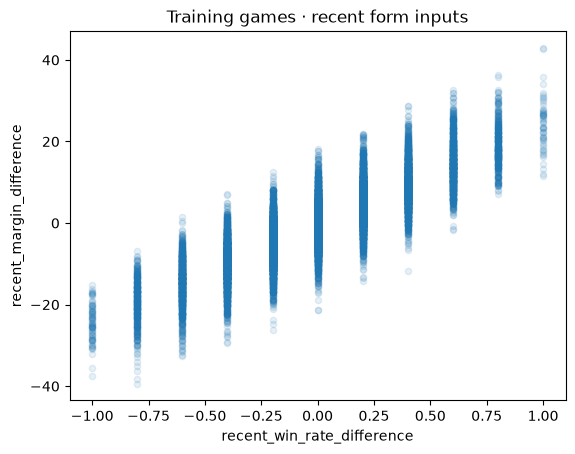

In [14]:
display(train[FEATURES + ["HOME_TEAM_WINS"]].corr().round(3))
train.plot.scatter(x="recent_win_rate_difference", y="recent_margin_difference", alpha=.11,
                   title="Training games · recent form inputs")
plt.show()

### 3.3 Summarize the final model partitions

Report the date span, sample size, and outcome frequency for each partition.

In [15]:
partition_profile = pd.DataFrame([
    {"partition": label, "rows": len(part), "first": part.date.min().date(),
     "last": part.date.max().date(), "home_win_rate": part.HOME_TEAM_WINS.mean()}
    for label, part in [("Train", train), ("Validation", validation), ("Test", test)]
])
display(partition_profile.round(4))

,partition,rows,first,last,home_win_rate
0,Train,16855,2003-11-07,2017-04-12,0.5962
1,Validation,1230,2017-10-17,2018-04-11,0.5789
2,Test,1230,2018-10-16,2019-04-10,0.5927


## 4. Model

Logistic regression estimates win probability from a weighted combination of the three features. A random forest averages predictions from multiple decision trees. The dummy baseline uses the training home-win rate for every game. Rank the two learned models using validation log loss, which penalizes confident wrong probabilities.

Both candidate settings are fixed before assessment. The scaled logistic regression uses C = 1. Treat the small validation gap as the selection rule for this experiment.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

target = "HOME_TEAM_WINS"
models = {
    "Home win rate": DummyClassifier(strategy="prior"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=35, random_state=255, n_jobs=2),
}
validation_loss = {}
for label, estimator in models.items():
    estimator.fit(train[FEATURES], train[target])
    validation_loss[label] = log_loss(validation[target], estimator.predict_proba(validation[FEATURES]))
display(pd.Series(validation_loss, name="validation_log_loss").sort_values().round(4))
selected = min(("Logistic regression", "Random forest"), key=validation_loss.get)
print("Selected from validation:", selected)

Logistic regression    0.6446
Random forest          0.6494
Home win rate          0.6813
Name: validation_log_loss, dtype: float64

Selected from validation: Logistic regression


### 4.1 Examine each model's validation predictions

Use the validation cohort to check probability spread and confirm the choice before refitting on development data.

In [17]:
validation_profiles = []
for label, estimator in models.items():
    p = estimator.predict_proba(validation[FEATURES])[:, 1]
    validation_profiles.append({
        "candidate": label, "log_loss": validation_loss[label],
        "accuracy_at_half": accuracy_score(validation[target], p >= .5),
        "probability_sd": np.std(p),
    })
display(pd.DataFrame(validation_profiles).sort_values("log_loss").round(4))

,candidate,log_loss,accuracy_at_half,probability_sd
1,Logistic regression,0.6446,0.6138,0.1342
2,Random forest,0.6494,0.6236,0.1355
0,Home win rate,0.6813,0.5789,0.0000


### 4.2 Interpret the logistic model

Show the coefficients on standardized training inputs. A coefficient describes the fitted association while holding the other inputs fixed.

In [18]:
fitted_logistic = models["Logistic regression"].named_steps["logisticregression"]
display(pd.Series(fitted_logistic.coef_[0], index=FEATURES, name="log_odds_per_training_sd").round(3))

recent_win_rate_difference    0.095
recent_margin_difference      0.504
rest_days_difference          0.065
Name: log_odds_per_training_sd, dtype: float64

Recent margin has the largest coefficient on the standardized inputs. Recent win rate and margin are related, so a small coefficient for win rate does not show that winning history is irrelevant.

## 5. Assess

Refit on training and validation data, then measure performance on 2018–19. Accuracy is the share of correct labels. ROC AUC measures how well the model ranks home wins above losses. Include a single historical game to show what the prediction looks like.

Compare the models with paired resamples of game dates. Keep the games on each sampled date together. The intervals describe uncertainty within this season and do not test performance across other seasons.

In [19]:
development = pd.concat([train, validation])
scores = {}
for label, estimator in models.items():
    estimator.fit(development[FEATURES], development[target])
    probability = estimator.predict_proba(test[FEATURES])[:, 1]
    scores[label] = {
        "accuracy": accuracy_score(test[target], probability >= 0.5),
        "log_loss": log_loss(test[target], probability),
        "roc_auc": roc_auc_score(test[target], probability),
    }
display(pd.DataFrame(scores).T.round(4))

rng = np.random.default_rng(255)
actual = test[target].to_numpy()
selected_p = models[selected].predict_proba(test[FEATURES])[:, 1]
interval_rows = []
for comparison in ("Home win rate", "Random forest"):
    other_p = models[comparison].predict_proba(test[FEATURES])[:, 1]
    difference = np.log(np.where(actual, other_p, 1 - other_p)) - np.log(np.where(actual, selected_p, 1 - selected_p))
    dates = pd.DataFrame({"date": test.date.to_numpy(), "difference": difference}).groupby("date").difference.agg(["sum", "size"])
    draws = rng.integers(0, len(dates), (1000, len(dates)))
    bootstrap = dates["sum"].to_numpy()[draws].sum(axis=1) / dates["size"].to_numpy()[draws].sum(axis=1)
    low, high = np.quantile(bootstrap, [.025, .975])
    interval_rows.append((comparison, difference.mean(), low, high))
comparison_intervals = pd.DataFrame(interval_rows, columns=["reference", "selected_minus_reference", "lower_95", "upper_95"])
display(comparison_intervals.round(4))

,accuracy,log_loss,roc_auc
Home win rate,0.5927,0.6759,0.5000
Logistic regression,0.6317,0.6373,0.6598
Random forest,0.6268,0.6417,0.6516


,reference,selected_minus_reference,lower_95,upper_95
0,Home win rate,-0.0386,-0.0553,-0.0217
1,Random forest,-0.0043,-0.0088,0.0004


In [20]:
example = test.sort_values(["date", "GAME_ID"]).iloc[[0]]
row = example.iloc[0]
example_result = {
    "date": str(row.date.date()),
    "home": team_names.loc[row.HOME_TEAM_ID],
    "away": team_names.loc[row.VISITOR_TEAM_ID],
    "model_home_win_probability": float(models[selected].predict_proba(example[FEATURES])[0, 1]),
    "actual_home_win": bool(row[target]),
}
display(pd.Series(example_result))
save_json("assessment.json", {
    "split_rows": {"train": len(train), "validation": len(validation), "test": len(test)},
    "selected": selected, "validation_log_loss": validation_loss,
    "metrics": scores, "paired_date_bootstrap": comparison_intervals.to_dict("records"), "example": example_result,
})

date                          2018-10-16
home                             Celtics
away                               76ers
model_home_win_probability      0.371332
actual_home_win                     True
dtype: object

Check the validation-selected model's calibration on the held-out season. Calibration compares mean predicted probability with the observed share of wins. Read the count before interpreting each group.

In [21]:
assessment_probability = models[selected].predict_proba(test[FEATURES])[:, 1]
calibration = pd.DataFrame({"predicted": assessment_probability, "home_won": test[target].to_numpy()})
bins = pd.cut(calibration.predicted, [0, .4, .5, .6, .7, 1], include_lowest=True)
display(calibration.groupby(bins, observed=True).agg(games=("home_won", "size"), mean_prediction=("predicted", "mean"), observed=("home_won", "mean")).round(4))

,games,mean_prediction,observed
predicted,,,
"(-0.001, 0.4]",125,0.3331,0.4000
"(0.4, 0.5]",217,0.4575,0.4470
"(0.5, 0.6]",273,0.5541,0.5568
"(0.6, 0.7]",318,0.6506,0.6352
"(0.7, 1.0]",297,0.7676,0.7677


The implementation uses Python in Colab and follows the five SEMMA stages. The comparison describes this held-out season. It does not establish that the winning model leads across all seasons.

### 5.1 Assess ranking and calibration visually

Compare the selected model's receiver operating characteristic with chance. Then plot mean prediction against the observed share of wins.

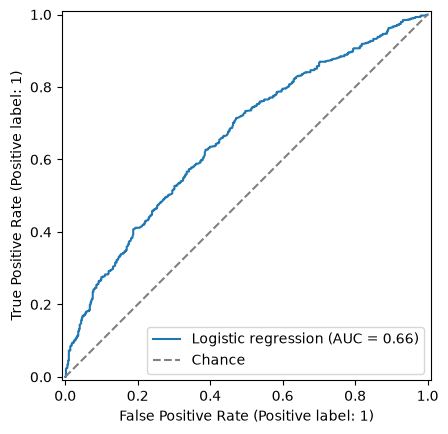

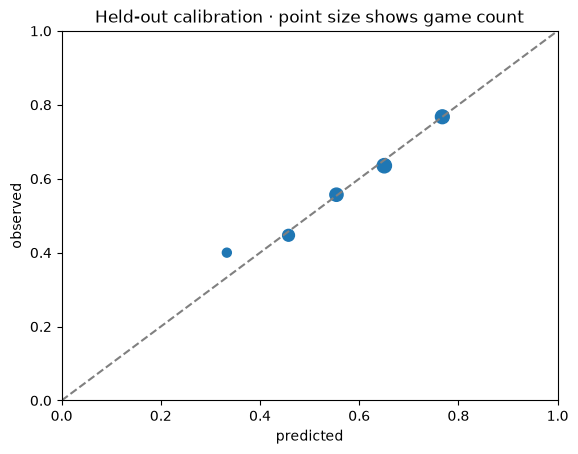

In [22]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(test[target], assessment_probability, name=selected)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.legend()
plt.show()

calibration_plot = calibration.groupby(bins, observed=True).agg(
    games=("home_won", "size"), predicted=("predicted", "mean"), observed=("home_won", "mean"),
)
ax = calibration_plot.plot.scatter(x="predicted", y="observed", s=calibration_plot.games / 3,
                                   title="Held-out calibration · point size shows game count")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set(xlim=(0, 1), ylim=(0, 1))
plt.show()

### 5.2 Check opening weeks separately

Prior-season form can matter most near opening day. Compare the first 14 calendar days with the remaining games without changing the fitted model.

In [23]:
opening_window = test.date.lt(test.date.min() + pd.Timedelta(days=14)).to_numpy()
slice_rows = []
for label, mask in [("Opening 14 days", opening_window), ("Remaining schedule", ~opening_window)]:
    p = assessment_probability[mask]
    y = test[target].to_numpy()[mask]
    slice_rows.append({"slice": label, "games": mask.sum(), "actual_win_rate": y.mean(),
                       "log_loss": log_loss(y, p, labels=[0, 1])})
display(pd.DataFrame(slice_rows).round(4))

,slice,games,actual_win_rate,log_loss
0,Opening 14 days,95,0.6211,0.6388
1,Remaining schedule,1135,0.5903,0.6372


Log loss was 0.6388 in the first 95 games and 0.6372 in the remaining 1,135. The estimates are close, but the opening-period sample is much smaller. This is a diagnostic slice of one season.

### 5.3 Examine errors and review the decision

Inspect the strongest wrong predictions. Keep the validation-selected model and report the held-out uncertainty versus the random forest.

In [24]:
wrong = (assessment_probability >= .5) != test[target].to_numpy()
error_table = test[["date", "HOME_TEAM_ID", "VISITOR_TEAM_ID", target]].assign(
    home_probability=assessment_probability,
    distance_from_half=abs(assessment_probability - .5),
)
error_table["home"] = error_table.HOME_TEAM_ID.map(team_names)
error_table["away"] = error_table.VISITOR_TEAM_ID.map(team_names)
display(error_table.loc[wrong].nlargest(6, "distance_from_half")[["date", "home", "away", target, "home_probability"]].round(3))

/var/folders/xf/wwxdg7jn6j5gqbs9jbs_3q3h0000gn/T/ipykernel_95926/2359159379.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(error_table.loc[wrong].nlargest(6, "distance_from_half")[["date", "home", "away", target, "home_probability"]].round(3))


,date,home,away,HOME_TEAM_WINS,home_probability
18602,2018-12-15,Spurs,Bulls,0,0.897
18980,2019-02-07,Celtics,Lakers,0,0.850
18750,2019-01-05,Bucks,Raptors,0,0.849
19041,2019-02-22,Magic,Bulls,0,0.836
18189,2018-10-19,Jazz,Warriors,0,0.827
18304,2018-11-04,Spurs,Magic,0,0.813
